### Notebook 03: Circular Flight Simulation

This notebook simulates the quadcopter flying along a circular path of radius 2 m at an altitude of 1 m and a speed of 0.5 m/s.

The simulation uses the 16-state dynamical model from `drone_model.py` and a PD controller to adjust the four individual motor torques.

The Design Engineer defined the circular trajectory as:

$$
x_d(t)=2\cos(0.25t)
$$

$$
y_d(t)=2\sin(0.25t), \qquad z_d(t)=1
$$

The drone's nose points toward the center of the circle, with its yaw angle given by:

$$
\psi_d(t)=\pi+0.25t
$$

The simulation runs for 70 seconds, allowing 10 seconds for initial stabilization followed by 60 seconds of circular flight verification.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid

import drone_model as drone

# Circular flight parameters
RADIUS = 2.0
SPEED = 0.5
ALTITUDE = 1.0

angular_speed = SPEED / RADIUS

# Hover conditions
hover_speed, hover_torque = drone.hover_conditions()

# Initial conditions
initial_state = np.zeros(16)

initial_state[0:3] = [2.05, -0.03, 0.98]
initial_state[3:6] = [0.0, 0.5, 0.0]

circle_pitch = np.arctan(
    SPEED**2 / (RADIUS * drone.GRAVITY)
)

initial_state[6] = np.radians(1)
initial_state[7] = circle_pitch
initial_state[8] = np.pi + np.radians(2)

initial_state[9] = -angular_speed * np.sin(circle_pitch)
initial_state[11] = angular_speed * np.cos(circle_pitch)

initial_state[12:16] = hover_speed

# Simulation time
simulation_time = 70
time_points = np.linspace(0, simulation_time, 1401)

print("Circular radius:", RADIUS, "m")
print("Flight speed:", SPEED, "m/s")
print("Angular speed:", angular_speed, "rad/s")
print("Initial pitch:", round(np.degrees(circle_pitch), 3), "deg")

Circular radius: 2.0 m
Flight speed: 0.5 m/s
Angular speed: 0.25 rad/s
Initial pitch: 0.73 deg


#### Circular Flight Control

To maintain circular motion, the drone must produce a horizontal acceleration directed toward the center of the circle.

The required centripetal acceleration is:

$$
a_c=\frac{v^2}{R}=\frac{0.5^2}{2}=0.125\ \mathrm{m/s^2}
$$

The controller compares the actual position and velocity with the desired circular trajectory:

$$
\mathbf{a}_{cmd}
=
\mathbf{a}_d
+
K_p(\mathbf{r}_d-\mathbf{r})
+
K_d(\mathbf{v}_d-\mathbf{v})
$$

The commanded acceleration determines the required thrust direction and desired attitude.

The controller then calculates the required roll, pitch, and yaw moments. These moments are converted into individual rotor speeds and motor torques using the same equations as Notebook 02.

Since the drone continuously turns while following the circle, the controller also accounts for the desired yaw rate of 0.25 rad/s.

In [2]:
# Controller gains
KP_XY = 2.0
KD_XY = 2.8

KP_Z = 3.0
KD_Z = 3.0

KP_ANGLE = 18.0
KD_ANGLE = 8.0

KP_YAW = 15.0
KD_YAW = 8.0

MOTOR_GAIN = 25.0

# Motor limits
MAX_RPM = 6530
MAX_SPEED = MAX_RPM * 2 * np.pi / 60
MAX_TORQUE = 0.14

k = drone.THRUST_COEFF
b = drone.DRAG_COEFF
L = drone.ARM_LENGTH

# Convert thrust and moments into rotor speeds
mixing_matrix = np.array([
    [k, k, k, k],
    [0, L*k, 0, -L*k],
    [-L*k, 0, L*k, 0],
    [-b, b, -b, b]
])


def circular_trajectory(time):
    angle = angular_speed * time

    position = np.array([
        RADIUS * np.cos(angle),
        RADIUS * np.sin(angle),
        ALTITUDE
    ])

    velocity = np.array([
        -SPEED * np.sin(angle),
        SPEED * np.cos(angle),
        0.0
    ])

    acceleration = np.array([
        -SPEED * angular_speed * np.cos(angle),
        -SPEED * angular_speed * np.sin(angle),
        0.0
    ])

    yaw = np.pi + angle

    return position, velocity, acceleration, yaw


def circle_controller(time, state):
    position, velocity, acceleration, yaw_target = circular_trajectory(time)

    current_position = state[0:3]
    current_velocity = state[3:6]

    roll, pitch, yaw = state[6:9]
    p, q, r = state[9:12]
    rotor_speeds = state[12:16]

    # Position control
    position_error = position - current_position
    velocity_error = velocity - current_velocity

    kp = np.array([KP_XY, KP_XY, KP_Z])
    kd = np.array([KD_XY, KD_XY, KD_Z])

    desired_acceleration = (
        acceleration
        + kp * position_error
        + kd * velocity_error
    )

    # Required thrust in ground coordinates
    force = drone.MASS * (
        desired_acceleration + np.array([0, 0, drone.GRAVITY])
    )

    force[2] = max(force[2], 0.1 * drone.MASS * drone.GRAVITY)

    total_thrust = np.linalg.norm(force)

    # Resolve thrust direction using desired yaw
    forward_force = (
        np.cos(yaw_target) * force[0]
        + np.sin(yaw_target) * force[1]
    )

    left_force = (
        -np.sin(yaw_target) * force[0]
        + np.cos(yaw_target) * force[1]
    )

    desired_roll = -np.arcsin(
        np.clip(left_force / total_thrust, -0.999, 0.999)
    )

    desired_pitch = np.arctan2(
        forward_force, force[2]
    )

    desired_roll = np.clip(desired_roll, -0.30, 0.30)
    desired_pitch = np.clip(desired_pitch, -0.30, 0.30)

    # Desired body rates during circular flight
    p_target = -np.sin(desired_pitch) * angular_speed

    q_target = (
        np.sin(desired_roll)
        * np.cos(desired_pitch)
        * angular_speed
    )

    r_target = (
        np.cos(desired_roll)
        * np.cos(desired_pitch)
        * angular_speed
    )

    # Keep yaw error between -pi and pi
    yaw_error = np.arctan2(
        np.sin(yaw_target - yaw),
        np.cos(yaw_target - yaw)
    )

    # Attitude control
    torque_x = drone.IX * (
        KP_ANGLE * (desired_roll - roll)
        + KD_ANGLE * (p_target - p)
    ) + (drone.IZ - drone.IY) * q * r

    torque_y = drone.IY * (
        KP_ANGLE * (desired_pitch - pitch)
        + KD_ANGLE * (q_target - q)
    ) + (drone.IX - drone.IZ) * p * r

    torque_z = drone.IZ * (
        KP_YAW * yaw_error
        + KD_YAW * (r_target - r)
    ) + (drone.IY - drone.IX) * p * q

    # Required thrust and body moments
    commands = np.array([
        total_thrust,
        torque_x,
        torque_y,
        torque_z
    ])

    # Calculate desired rotor speeds
    speed_squared = np.linalg.solve(mixing_matrix, commands)
    speed_squared = np.clip(speed_squared, 0, MAX_SPEED**2)

    desired_speeds = np.sqrt(speed_squared)

    # Convert desired rotor speeds into motor torques
    motor_torques = (
        b * rotor_speeds**2
        + drone.ROTOR_INERTIA * MOTOR_GAIN
        * (desired_speeds - rotor_speeds)
    )

    motor_torques = np.clip(motor_torques, 0, MAX_TORQUE)

    return motor_torques

In [3]:
def controlled_dynamics(time, state):
    motor_torques = circle_controller(time, state)
    return drone.drone_derivatives(time, state, motor_torques)


solution = solve_ivp(
    controlled_dynamics,
    (0, simulation_time),
    initial_state,
    t_eval=time_points,
    rtol=1e-7,
    atol=1e-9,
    max_step=0.05
)

assert solution.success, solution.message

print("Solver successful:", solution.success)
print("Simulation duration:", solution.t[-1], "s")
print("Final position:", solution.y[0:3, -1])
print("Final attitude:", np.degrees(solution.y[6:9, -1]))

Solver successful: True
Simulation duration: 70.0 s
Final position: [ 0.43887993 -1.95125201  1.        ]
Final attitude: [9.33719788e-09 7.30029062e-01 1.18267614e+03]


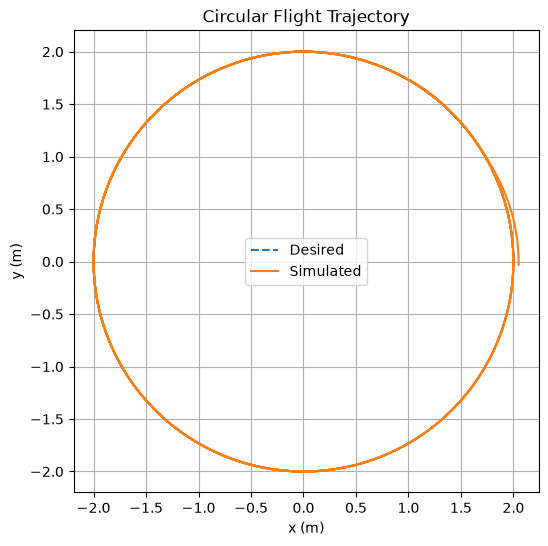

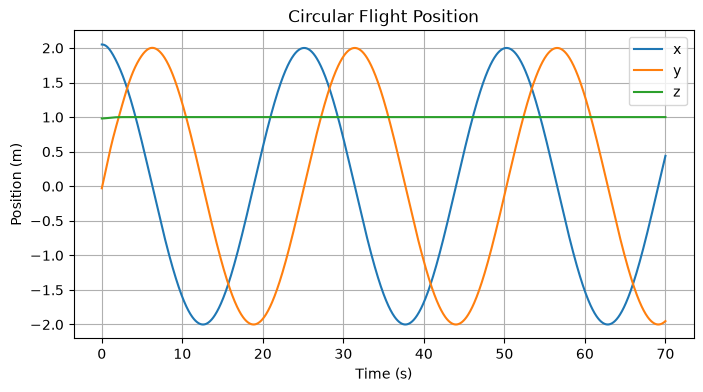

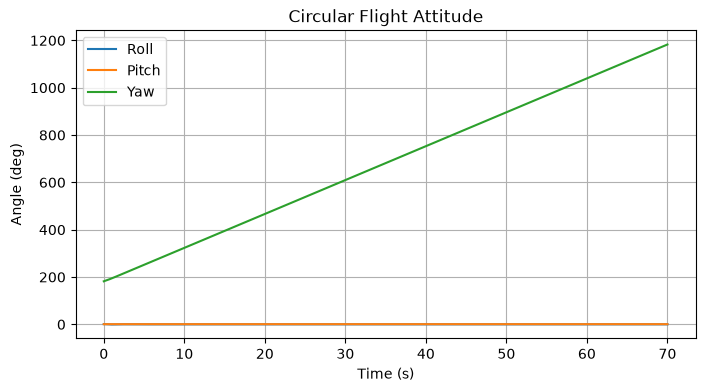

In [4]:
time = solution.t

x = solution.y[0]
y = solution.y[1]
z = solution.y[2]

roll = np.degrees(solution.y[6])
pitch = np.degrees(solution.y[7])
yaw = np.degrees(solution.y[8])

# Calculate reference trajectory
reference_x = RADIUS * np.cos(angular_speed * time)
reference_y = RADIUS * np.sin(angular_speed * time)

# Horizontal circular trajectory
plt.figure(figsize=(6, 6))
plt.plot(reference_x, reference_y, "--", label="Desired")
plt.plot(x, y, label="Simulated")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Circular Flight Trajectory")
plt.axis("equal")
plt.legend()
plt.grid()
plt.show()

# Position over time
plt.figure(figsize=(8, 4))
plt.plot(time, x, label="x")
plt.plot(time, y, label="y")
plt.plot(time, z, label="z")
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Circular Flight Position")
plt.legend()
plt.grid()
plt.show()

# Attitude over time
plt.figure(figsize=(8, 4))
plt.plot(time, roll, label="Roll")
plt.plot(time, pitch, label="Pitch")
plt.plot(time, yaw, label="Yaw")
plt.xlabel("Time (s)")
plt.ylabel("Angle (deg)")
plt.title("Circular Flight Attitude")
plt.legend()
plt.grid()
plt.show()

In [6]:
# Check the final 60 seconds
flight_time = time >= 10

vx = solution.y[3]
vy = solution.y[4]
vz = solution.y[5]

# Radius and speed
radius = np.sqrt(x**2 + y**2)
speed = np.sqrt(vx**2 + vy**2 + vz**2)

# Position tracking error
tracking_error = np.sqrt(
    (x - reference_x)**2
    + (y - reference_y)**2
    + (z - ALTITUDE)**2
)

# Maximum errors during verification period
radius_error = np.max(np.abs(radius[flight_time] - RADIUS))
altitude_error = np.max(np.abs(z[flight_time] - ALTITUDE))
speed_error = np.max(np.abs(speed[flight_time] - SPEED))
position_error = np.max(tracking_error[flight_time])

print("Maximum radius error:", round(radius_error, 4), "m")
print("Maximum altitude error:", round(altitude_error, 4), "m")
print("Maximum speed error:", round(speed_error, 4), "m/s")
print("Maximum position error:", round(position_error, 4), "m")

# Verify circular flight requirements
circle_pass = (
    radius_error < 0.05
    and altitude_error < 0.05
    and speed_error < 0.05
    and position_error < 0.05
)

print("60-second circular flight passed:", circle_pass)

# Electrical power and energy
power = []

for i in range(len(time)):
    speeds = solution.y[12:16, i]
    power.append(drone.electrical_power(speeds))

power = np.array(power)

flight_energy = trapezoid(
    power[flight_time],
    time[flight_time]
) / 3600

total_energy = trapezoid(power, time) / 3600

usable_energy = (
    drone.BATTERY_VOLTAGE
    * drone.BATTERY_CAPACITY
    * (1 - drone.BATTERY_RESERVE)
)

print("Circular flight energy:", round(flight_energy, 3), "Wh")
print("Total simulation energy:", round(total_energy, 3), "Wh")
print("Usable battery energy:", round(usable_energy, 2), "Wh")
print("Energy requirement passed:", total_energy < usable_energy)

# Motor limits
motor_inputs = []

for i in range(len(time)):
    motor_inputs.append(
        circle_controller(time[i], solution.y[:, i])
    )

motor_inputs = np.array(motor_inputs)

max_rpm = np.max(solution.y[12:16]) * 60 / (2 * np.pi)
max_torque = np.max(motor_inputs)

print("Maximum rotor speed:", round(max_rpm, 1), "RPM")
print("Maximum motor torque:", round(max_torque, 4), "Nm")

print("Rotor speed limit passed:", max_rpm <= MAX_RPM)
print("Motor torque limit passed:", max_torque <= MAX_TORQUE)

Maximum radius error: 0.0005 m
Maximum altitude error: 0.0 m
Maximum speed error: 0.0013 m/s
Maximum position error: 0.0006 m
60-second circular flight passed: True
Circular flight energy: 2.391 Wh
Total simulation energy: 2.789 Wh
Usable battery energy: 44.4 Wh
Energy requirement passed: True
Maximum rotor speed: 4326.5 RPM
Maximum motor torque: 0.0612 Nm
Rotor speed limit passed: True
Motor torque limit passed: True
